In [2]:
import os

print(os.getcwd())

c:\Users\ahama\OneDrive\Bureau\Paul_Valery\TER\DONNEES


In [3]:
print(os.listdir())

['broaderRelationsOccPillar_fr.csv', 'broaderRelationsSkillPillar_fr.csv', 'dictionary_fr.csv', 'digCompSkillsCollection_fr.csv', 'digitalSkillsCollection_fr.csv', 'exploration_esco.ipynb', 'greenShareOcc_fr.csv', 'greenSkillsCollection_fr.csv', 'ISCOGroups_fr.csv', 'languageSkillsCollection_fr.csv', 'occupationSkillRelations_fr.csv', 'occupations_fr.csv', 'researchOccupationsCollection_fr.csv', 'researchSkillsCollection_fr.csv', 'skillGroups_fr.csv', 'skillsHierarchy_fr.csv', 'skillSkillRelations_fr.csv', 'skills_fr.csv', 'transversalSkillsCollection_fr.csv']


In [1]:
import pandas as pd

df = pd.read_csv("../../data/raw/skills_fr.csv", encoding="utf-8")

df.head()

,conceptType,conceptUri,skillType,reuseLevel,preferredLabel,altLabels,hiddenLabels,status,modifiedDate,scopeNote,definition,inScheme,description
0,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/0005c151-5b5a...,skill/competence,sector-specific,gérer le personnel musical,NaN,NaN,released,2023-11-30T15:53:37.136Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Attribuer et gérer les tâches du personnel dan...
1,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/00064735-8fad...,skill/competence,occupation-specific,superviser des procédures correctionnelles,NaN,NaN,released,2023-11-30T15:04:00.689Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Superviser les opérations d’un établissement c...
2,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/000709ed-2be5...,skill/competence,sector-specific,appliquer des pratiques de travail social anti...,NaN,NaN,released,2023-11-28T10:45:53.54Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,"Identifier l’oppression dans les sociétés, les..."
3,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/0007bdc2-dd15...,skill/competence,sector-specific,contrôler la conformité à la réglementation su...,NaN,NaN,released,2023-11-30T16:29:18.273Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,"Inspecter le matériel roulant, les composants ..."
4,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/00090cc1-1f27...,skill/competence,cross-sector,recenser les services disponibles,NaN,NaN,released,2023-11-28T10:38:49.206Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Identifier les différents services disponibles...


# 1. les dimensions du fichier

In [5]:
df.shape

(13960, 13)

## 2. Distinguer les compétences des connaissances

ESCO distingue notamment les connaissances (knowledge) et les compétences pratiques (skill/competence).
Nous allons compter combien d'enregistrements appartiennent à chaque catégorie.

In [6]:
df["skillType"].value_counts()

skillType
skill/competence    10734
knowledge            3221
Name: count, dtype: int64

## 3. Vérifions les valeurs manquantes

In [7]:
df["skillType"].value_counts(dropna=False)

skillType
skill/competence    10734
knowledge            3221
NaN                     5
Name: count, dtype: int64

## 3.1. Examiner les 5 lignes manquantes concernées

In [8]:
df[df["skillType"].isna()]

,conceptType,conceptUri,skillType,reuseLevel,preferredLabel,altLabels,hiddenLabels,status,modifiedDate,scopeNote,definition,inScheme,description
3627,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/426ceaba-6867...,NaN,NaN,sécurité des TIC,sécurité des technologies de l'information et ...,NaN,released,2025-02-27T12:45:08.961Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,"Protection des personnes, protection des donné..."
4797,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/574257ea-7b64...,NaN,NaN,communication et collaboration numériques,NaN,NaN,released,2025-02-27T12:45:08.961Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Communiquer dans des environnements numériques...
5430,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/629685b8-5f9e...,NaN,NaN,traitement de données numériques,NaN,NaN,released,2025-02-27T12:45:08.961Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,"Déterminer, localiser, rechercher, stocker, or..."
6962,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/7e5147d1-60b1...,NaN,NaN,résolution des problèmes à l'aide d'outils et ...,NaN,NaN,released,2025-02-27T12:45:08.961Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Déterminer les besoins et les ressources numér...
13346,KnowledgeSkillCompetence,http://data.europa.eu/esco/skill/f5369f2f-e52b...,NaN,NaN,création de contenus numériques,NaN,NaN,released,2025-02-27T12:45:08.961Z,NaN,NaN,http://data.europa.eu/esco/concept-scheme/skil...,Créer et modifier de nouveaux contenus (du tra...


## 3.2. Que représentent ces 5 lignes ?

Regardons les intitulés (preferredLabel) :

Ligne	Intitulé
3627	Sécurité des TIC
4797	Communication et collaboration numériques
5430	Traitement de données numériques
6962	Résolution des problèmes à l'aide d'outils et de technologies numériques
13346	Création de contenus numériques

On remarque que ces cinq éléments concernent tous les compétences numériques.

Ils semblent correspondre à de grandes catégories de compétences numériques, plutôt qu'à des compétences individuelles. Cela pourrait expliquer pourquoi skillType et reuseLevel ne sont pas renseignés.

Cependant, nous ne pouvons pas encore confirmer cette explication uniquement à partir du tableau.

Pour notre TER : nous allons conserver ces cinq enregistrements pour le moment, plutôt que de les supprimer.

## 4. Étape suivante : explorer reuseLevel

Cette colonne indique le niveau de réutilisation d'une compétence dans différents contextes professionnels.

In [9]:
df["reuseLevel"].value_counts(dropna=False)

reuseLevel
sector-specific        6667
cross-sector           3788
occupation-specific    3047
transversal             453
NaN                       5
Name: count, dtype: int64

*Voici ce que signifient ces catégories :*

Catégorie   	Nombre	Signification
sector-specific 	6 667	Compétences propres à un secteur d'activité
cross-sector    	3 788	Compétences utilisables dans plusieurs secteurs
occupation-specific 	3 047	Compétences propres à certains métiers
transversal 	453	Compétences générales mobilisables dans de nombreux contextes
NaN	5   	Niveau non renseigné

# Pourquoi est-ce intéressant pour notre TER ?

Notre objectif est d'aligner les compétences présentes dans les offres d'emploi avec celles du référentiel ESCO.

Cette classification pourra nous aider à comprendre si une compétence identifiée dans une offre est générale ou davantage liée à un métier ou à un secteur.

Par exemple, une compétence transversale peut apparaître dans des offres de métiers très différents, tandis qu'une compétence spécifique à un métier sera généralement plus ciblée.

## 5. Étape suivante : vérifier les identifiants ESCO

Chaque compétence possède un identifiant dans la colonne conceptUri. C'est cet identifiant qui permettra notamment de relier les compétences aux métiers dans les autres fichiers ESCO.

Nous allons vérifier si ces identifiants sont uniques.

In [10]:
df["conceptUri"].nunique()

13939

Nous venons de détecter un point à examiner dans notre fichier ESCO.

Nous avons :
- 13 960 lignes dans skills_fr.csv.
- 13 939 identifiants distincts dans conceptUri.
- Une différence de 21 lignes.

Cela peut indiquer que certains identifiants apparaissent plusieurs fois. Mais attention : nunique() ne compte pas les valeurs manquantes par défaut.

Nous allons donc vérifier cela avant de conclure.

## 5.1. Étape suivante : rechercher les doublons

In [11]:
df["conceptUri"].isna().sum()

np.int64(0)

In [12]:
df["conceptUri"].duplicated().sum()

np.int64(21)

Nous avons maintenant confirmé deux choses :
- 0 identifiant manquant dans conceptUri.
- 21 occurrences en doublon dans cette colonne.

Cela signifie que, parmi les 13 960 lignes du fichier, certains identifiants ESCO apparaissent plusieurs fois.

Attention : cela ne signifie pas nécessairement que les données sont incorrectes. Nous devons comprendre pourquoi ces identifiants se répètent.

## 5.2. Étape suivante : examiner les doublons

In [13]:
doublons = df[df["conceptUri"].duplicated(keep=False)]

doublons[["conceptUri", "preferredLabel", "skillType", "reuseLevel"]]

,conceptUri,preferredLabel,skillType,reuseLevel
961,http://data.europa.eu/esco/skill/11dc8e6b-dffa...,faire fonctionner l’équipement de pompage,skill/competence,sector-specific
962,http://data.europa.eu/esco/skill/11dc8e6b-dffa...,faire fonctionner l’équipement de pompage,skill/competence,sector-specific
986,http://data.europa.eu/esco/skill/1258cc12-37bb...,travailler de façon organisée,skill/competence,cross-sector
987,http://data.europa.eu/esco/skill/1258cc12-37bb...,travailler de façon organisée,skill/competence,cross-sector
1023,http://data.europa.eu/esco/skill/1330576d-b3c7...,mettre en œuvre les plans d’urgence d’un aéroport,skill/competence,sector-specific
1024,http://data.europa.eu/esco/skill/1330576d-b3c7...,mettre en œuvre les plans d’urgence d’un aéroport,skill/competence,sector-specific
1387,http://data.europa.eu/esco/skill/19c610ff-f8eb...,évaluer les données recueillies pour améliorer...,skill/competence,occupation-specific
1388,http://data.europa.eu/esco/skill/19c610ff-f8eb...,évaluer les données recueillies pour améliorer...,skill/competence,occupation-specific
1491,http://data.europa.eu/esco/skill/1b9899a4-5b50...,évaluer l’état physique des clients,skill/competence,cross-sector
1492,http://data.europa.eu/esco/skill/1b9899a4-5b50...,évaluer l’état physique des clients,skill/competence,cross-sector


## Ce que nous observons

Le tableau montre que les 21 identifiants répétés apparaissent chacun deux fois, soit 42 lignes concernées.

Par exemple :
Compétence	Lignes
SQL	4911 et 4912
Travailler de façon organisée	986 et 987
Gérer des rendez-vous	8106 et 8107
Mémoriser des informations	13629 et 13630

Pour chaque paire, les colonnes affichées (conceptUri, preferredLabel, skillType, reuseLevel) semblent identiques.

Mais cela ne prouve pas encore que les 13 colonnes sont identiques. Il est possible que les descriptions ou d'autres informations diffèrent.

## 6. Étape suivante : vérifier si les lignes sont entièrement identiques

In [14]:
df.duplicated().sum()

np.int64(0)

*Cela signifie qu'il n'existe aucune ligne entièrement identique dans les 13 colonnes du fichier.*

Récapitulons :
Vérification	Résultat
Nombre total de lignes	13 960
Identifiants conceptUri distincts	13 939
Occurrences répétées d'identifiants	21
Lignes entièrement identiques	0

*Conclusion :* certaines compétences possèdent le même identifiant ESCO, mais leurs enregistrements diffèrent dans au moins une colonne.

Nous devons identifier ces différences avant d'envisager un nettoyage.

## 6.1. Éape suivante : comparer deux lignes

In [15]:
df.loc[[4911, 4912]].T

,4911,4912
conceptType,KnowledgeSkillCompetence,KnowledgeSkillCompetence
conceptUri,http://data.europa.eu/esco/skill/598de5b0-5b58...,http://data.europa.eu/esco/skill/598de5b0-5b58...
skillType,knowledge,knowledge
reuseLevel,sector-specific,sector-specific
preferredLabel,SQL,SQL
altLabels,Subquery\nInformix 4GL/SQL\nSEQUEL,Subquery\nInformix 4GL/SQL\nSEQUEL
hiddenLabels,NaN,NaN
status,released,released
modifiedDate,2025-07-31T09:45:14.168Z,2025-11-26T10:14:58.688Z
scopeNote,NaN,NaN


## Ce que montre le tableau

Les lignes 4911 et 4912 ont le même identifiant ESCO et le même intitulé : SQL.

En revanche, leurs dates de modification sont différentes :
Ligne	modifiedDate
4911	31 juillet 2025
4912	26 novembre 2025

Cela suggère que le fichier contient deux enregistrements d'une même compétence, avec des dates de modification différentes.

Attention : les descriptions sont tronquées dans l'affichage. Nous ne pouvons donc pas encore affirmer que seule la date change.

## 6.2. Étape suivante : identifier exactement les colonnes différentes

In [16]:
ligne1 = df.loc[4911]
ligne2 = df.loc[4912]

for colonne in df.columns:
    if not (ligne1[colonne] == ligne2[colonne] or
            (pd.isna(ligne1[colonne]) and pd.isna(ligne2[colonne]))):
        print(colonne)

modifiedDate


Nous avons confirmé que, pour la compétence SQL, la seule différence entre les deux lignes est la date de modification (modifiedDate).

Cela signifie que les autres informations sont identiques : intitulé, description, type de compétence, etc.

Pour notre projet TER, c'est intéressant : nous pourrions conserver la version la plus récente de chaque compétence. Mais avant de décider, 
vérifions si c'est également le cas pour les 20 autres identifiants répétés.

## 6.3. Étape suivante : vérifier tous les doublons

In [17]:
colonnes = df.columns.drop("modifiedDate")

df.duplicated(subset=colonnes).sum()

np.int64(21)

## Ce que nous avons découvert

Sur les 13 960 lignes de skills_fr.csv :
- 13 939 identifiants ESCO sont distincts.
- 21 occurrences supplémentaires possèdent un identifiant déjà présent.
- Ces 21 répétitions sont identiques sur les 12 autres colonnes, à l'exception de modifiedDate.

Conclusion : les doublons ne diffèrent que par leur date de modification.

Pour préparer notre base locale, nous pouvons donc conserver l'enregistrement le plus récent de chaque compétence.

## 7. Étape suivante : créer une version nettoyée

*Explication*

1. sort_values("modifiedDate") trie les enregistrements selon leur date de modification.
2. drop_duplicates(subset="conceptUri", keep="last") conserve uniquement la dernière occurrence de chaque identifiant, donc la plus récente.
3. df_skills.shape affiche les dimensions de notre nouvelle base.

Comme les dates sont au format ISO dans ce fichier, leur tri alphabétique correspond à leur ordre chronologique.

In [18]:
df_skills = df.sort_values("modifiedDate").drop_duplicates(
    subset="conceptUri",
    keep="last"
)

df_skills.shape

(13939, 13)

Notre DataFrame df_skills contient désormais 13 939 compétences et connaissances distinctes, contre 13 960 lignes initialement.

Nous avons conservé les enregistrements les plus récents lorsque plusieurs lignes partageaient le même identifiant conceptUri, sans modifier le fichier CSV original.

## 8. Étape suivante : explorer les métiers ESCO

Nous allons maintenant travailler avec le fichier *occupations_fr.csv*.

C'est une étape importante pour notre TER, puisque notre objectif est de faire correspondre les compétences demandées dans les offres d'emploi avec celles du référentiel ESCO.

In [ ]:
df_occupations = pd.read_csv("../../data/raw/occupations_fr.csv", encoding="utf-8")

df_occupations.head()

,conceptType,conceptUri,iscoGroup,preferredLabel,altLabels,hiddenLabels,status,modifiedDate,regulatedProfessionNote,scopeNote,definition,inScheme,description,code,naceCode
0,Occupation,http://data.europa.eu/esco/occupation/00030d09...,2654,directeur technique/directrice technique,régisseuse\nrégisseur/régisseuse\nrégisseur\nd...,NaN,released,2024-01-25T11:28:50.295Z,http://data.europa.eu/esco/regulated-professio...,NaN,NaN,http://data.europa.eu/esco/concept-scheme/memb...,Les directeurs techniques/directrices techniqu...,2654.1.7,http://data.europa.eu/ux2/nace2.1/9031
1,Occupation,http://data.europa.eu/esco/occupation/000e93a3...,8121,opérateur de tréfilerie/opératrice de tréfilerie,opérateur de tréfilerie\nopératrice de tréfilerie,NaN,released,2024-01-23T10:09:32.099Z,http://data.europa.eu/esco/regulated-professio...,NaN,NaN,http://data.europa.eu/esco/concept-scheme/memb...,Les opérateurs de tréfilerie installent et fon...,8121.4,http://data.europa.eu/ux2/nace2.1/242
2,Occupation,http://data.europa.eu/esco/occupation/0019b951...,7543,contrôleur qualité des instruments de précisio...,contrôleur qualité des instruments de précisio...,NaN,released,2024-01-25T15:00:12.188Z,http://data.europa.eu/esco/regulated-professio...,NaN,NaN,http://data.europa.eu/esco/concept-scheme/memb...,Les contrôleurs qualité des instruments de pré...,7543.10.3,http://data.europa.eu/ux2/nace2.1/2651
3,Occupation,http://data.europa.eu/esco/occupation/0022f466...,3155,technicien de la sécurité du trafic aérien/tec...,technicienne de la sécurité du trafic aérien\n...,NaN,released,2024-01-29T16:01:13.998Z,http://data.europa.eu/esco/regulated-professio...,NaN,NaN,http://data.europa.eu/esco/concept-scheme/memb...,Les techniciens de la sécurité aérienne apport...,3155.1,http://data.europa.eu/ux2/nace2.1/5223
4,Occupation,http://data.europa.eu/esco/occupation/002da35b...,2431,gestionnaire de recettes dans le secteur Horeca,yield manager\ngestionnaire des revenus hôteli...,NaN,released,2024-01-11T10:28:45.871Z,http://data.europa.eu/esco/regulated-professio...,NaN,NaN,http://data.europa.eu/esco/concept-scheme/memb...,Les gestionnaires de recettes dans le secteur ...,2431.9,"http://data.europa.eu/ux2/nace2.1/701,\nhttp:/..."


## Comprendre les colonnes

Dans les cinq premières lignes, nous retrouvons notamment :
Colonne 	Signification
conceptUri  	Identifiant unique attendu pour chaque métier ESCO
preferredLabel  	Nom principal du métier en français
altLabels   	Autres appellations possibles du métier
description 	Description des activités du métier
iscoGroup   	Groupe professionnel selon la classification ISCO
code    	Code du métier dans ESCO
naceCode    	Code du secteur d'activité économique associé
modifiedDate    	Date de dernière modification de l'enregistrement

Pourquoi ces informations sont-elles importantes pour notre TER ?

Prenons l'exemple d'une offre d'emploi intitulée « Data Analyst ».

Notre système devra pouvoir identifier le métier correspondant dans ESCO, puis retrouver les compétences qui lui sont associées.

C'est précisément pour cela que nous explorons les trois fichiers :

*occupations_fr.csv*
Les métiers ESCO
        |
*occupationSkillRelations_fr.csv*
Les relations entre métiers et compétences
        |
*skills_fr.csv*
Les compétences et connaissances ESCO

## 8.1. Étape suivante : compter les métiers

Avant d'étudier les relations, nous devons connaître le nombre de métiers présents dans notre fichier.

In [20]:
df_occupations.shape

(3043, 15)

Fichier	                Nombre de lignes	    Nombre de colonnes
skills_fr.csv (nettoyé)	    13 939	                    13
occupations_fr.csv	         3 043	                    15

Cela signifie que notre fichier des métiers contient *3 043 enregistrements*, décrits par 15 variables.

## 8.2. Étape suivante : vérifier les identifiants des métiers

Comme pour les compétences, nous devons vérifier que chaque métier possède un identifiant ESCO unique.

## Pourquoi cette vérification ?

La colonne conceptUri nous servira à relier les métiers à leurs compétences dans occupationSkillRelations_fr.csv.

Nous voulons donc savoir si elle peut être utilisée comme clé unique dans notre table des métiers.

In [21]:
print("Identifiants distincts :", df_occupations["conceptUri"].nunique())

print("Identifiants manquants :", df_occupations["conceptUri"].isna().sum())

print("Doublons :", df_occupations["conceptUri"].duplicated().sum())

Identifiants distincts : 3039
Identifiants manquants : 0
Doublons : 4


## 8.3. Interprétation des résultats

Vérification        	Résultat
Nombre total de lignes	3 043
Identifiants distincts	3 039
Identifiants manquants	0
Occurrences en doublon	4

Cela signifie que 4 lignes supplémentaires possèdent un identifiant conceptUri déjà présent.

Mais nous ne savons pas encore si ces enregistrements diffèrent uniquement par leur date de modification, comme dans skills_fr.csv.

Il ne faut donc pas les supprimer immédiatement.

## 8.4. Étape suivante : examiner les doublons

In [22]:
doublons_metiers = df_occupations[
    df_occupations["conceptUri"].duplicated(keep=False)
]

doublons_metiers[
    ["conceptUri", "preferredLabel", "modifiedDate"]
]

,conceptUri,preferredLabel,modifiedDate
959,http://data.europa.eu/esco/occupation/4d27152a...,assistant pédagogique en école maternelle/assi...,2025-07-31T09:38:59.122Z
960,http://data.europa.eu/esco/occupation/4d27152a...,assistant pédagogique en école maternelle/assi...,2025-11-26T10:02:16.164Z
1168,http://data.europa.eu/esco/occupation/5d601b40...,chargé de mission affaires juridiques/chargée ...,2025-07-31T09:38:50.084Z
1169,http://data.europa.eu/esco/occupation/5d601b40...,chargé de mission affaires juridiques/chargée ...,2025-11-26T10:02:36.927Z
2121,http://data.europa.eu/esco/occupation/ad404c6b...,responsable de la logistique distribution de m...,2025-07-31T09:40:29.933Z
2122,http://data.europa.eu/esco/occupation/ad404c6b...,responsable de la logistique distribution de m...,2025-11-26T10:03:23.138Z
2209,http://data.europa.eu/esco/occupation/b4bff870...,travailleur des services de restauration/trava...,2025-07-31T09:41:03.211Z
2210,http://data.europa.eu/esco/occupation/b4bff870...,travailleur des services de restauration/trava...,2025-11-26T10:03:40.525Z


## a. Analyse du résultat

Pour chacun de ces métiers, nous observons deux dates de modification :
- Une première en juillet 2025.
- Une seconde en novembre 2025.

Les intitulés et les identifiants semblent identiques.

Cela ressemble à ce que nous avions observé dans skills_fr.csv, mais nous devons encore vérifier les autres colonnes avant de conclure.

## b. Étape suivante : vérifier si seule la date change

Nous recherchons les lignes identiques en comparant les 14 colonnes autres que modifiedDate.

- Si le résultat est 4 : les quatre répétitions sont identiques sur les autres colonnes. Nous pourrons alors conserver la version la plus récente de chaque métier.
- Si le résultat est inférieur à 4 : certaines répétitions présentent d'autres différences qu'il faudra examiner.

In [23]:
colonnes = df_occupations.columns.drop("modifiedDate")

df_occupations.duplicated(subset=colonnes).sum()

np.int64(4)

Nous avons confirmé que les 4 doublons du fichier occupations_fr.csv ne diffèrent que par leur date de modification *(modifiedDate)*.

Nous pouvons donc appliquer la même méthode de nettoyage que pour les compétences ESCO.

## 9. Étape suivante : nettoyer la table des métiers

In [24]:
df_occupations = df_occupations.sort_values("modifiedDate").drop_duplicates(
    subset="conceptUri",
    keep="last"
)

df_occupations.shape

(3039, 15)

Nous avons terminé la première préparation des deux tables principales du référentiel ESCO.

Table	                    Nombre d'enregistrements
Compétences (df_skills)	            13 939
Métiers (df_occupations)	         3 039

Les identifiants sont maintenant uniques dans chacune de ces deux tables.

## 10. Étape suivante : explorer les relations entre métiers et compétences

Nous allons maintenant ouvrir le fichier occupationSkillRelations_fr.csv.

C'est l'un des fichiers les plus importants pour notre TER, car il permet d'identifier les compétences associées à chaque métier ESCO.

Par exemple, nous pourrons rechercher les compétences associées au métier de data analyst.

## Pourquoi ce fichier est-il important ?

Nous avons maintenant trois éléments complémentaires :
- *df_occupations :* les métiers.
- *df_skills :* les compétences et connaissances.
- *df_relations :* les associations entre les métiers et les compétences.

Grâce à ces trois tables, nous pourrons ensuite construire une base locale permettant de retrouver les compétences attendues pour un métier donné.

In [ ]:
df_relations = pd.read_csv("../../data/raw/occupationSkillRelations_fr.csv", encoding="utf-8")

df_relations.head()

,occupationUri,occupationLabel,relationType,skillType,skillUri,skillLabel
0,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,knowledge,http://data.europa.eu/esco/skill/fed5b267-73fa...,theatre techniques
1,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,skill/competence,http://data.europa.eu/esco/skill/05bc7677-5a64...,organise rehearsals
2,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,skill/competence,http://data.europa.eu/esco/skill/271a36a0-bc7a...,write risk assessment on performing arts produ...
3,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,skill/competence,http://data.europa.eu/esco/skill/47ed1d37-971b...,coordinate with creative departments
4,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,skill/competence,http://data.europa.eu/esco/skill/591dd514-735b...,adapt to artists' creative demands


## Comprendre les colonnes

Ton tableau contient 6 colonnes :
Colonne	                Signification
occupationUri	    Identifiant ESCO du métier
occupationLabel	        Nom du métier
relationType	    Type de relation entre le métier et la compétence
skillType	        Compétence pratique ou connaissance
skillUri	        Identifiant ESCO de la compétence
skillLabel	        Nom de la compétence

## Une colonne particulièrement importante : *relationType*
Dans ton tableau, nous observons la valeur essential.
ESCO distingue notamment deux types de relations :
- essential : compétence considérée comme essentielle pour exercer le métier.
- optional : compétence complémentaire qui peut être utile pour exercer le métier.
Par exemple, pour le métier technical director, les premières lignes présentent des compétences essentielles comme l'organisation des répétitions et la coordination avec les départements créatifs.
Tu remarqueras aussi que les intitulés du fichier des relations sont en anglais, alors que ceux de occupations_fr.csv et skills_fr.csv sont en français.
Ce n'est pas bloquant : nous pourrons utiliser les identifiants occupationUri et skillUri pour retrouver les intitulés français dans nos deux autres tables.

## 10.1. Étape suivante : connaître les dimensions du fichier

In [26]:
df_relations.shape

(126051, 6)

Cela signifie que le fichier *occupationSkillRelations_fr.csv* contient :
- 126 051 relations entre métiers et compétences.
- 6 colonnes décrivant ces relations.
Attention : 126 051 relations ne signifient pas 126 051 compétences différentes. Une même compétence peut être associée à plusieurs métiers.

## 11. Étape suivante : analyser les types de relations

La colonne relationType permet de distinguer :
- essential : les compétences et connaissances essentielles à un métier.
- optional : les compétences et connaissances optionnelles pour ce métier.

La commande *value_counts(dropna=False)* compte chaque catégorie, y compris les éventuelles valeurs manquantes.

In [27]:
df_relations["relationType"].value_counts(dropna=False)

relationType
essential    67600
optional     58451
Name: count, dtype: int64

## Illustration du resultat

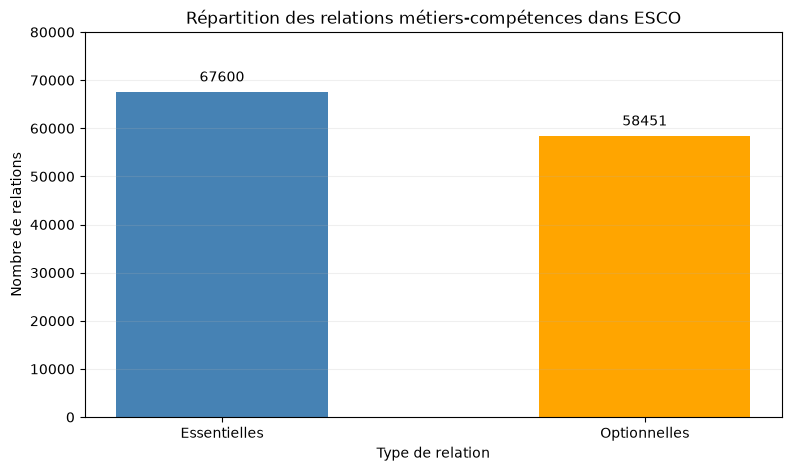

In [28]:
import matplotlib.pyplot as plt

# Compter les types de relations
repartition = df_relations["relationType"].value_counts()

# Créer le diagramme
plt.figure(figsize=(9, 5))

barres = plt.bar(
    ["Essentielles", "Optionnelles"],
    [repartition["essential"], repartition["optional"]],
    color=["steelblue", "orange"],
    width=0.5
)

# Ajouter les valeurs au-dessus des barres
plt.bar_label(barres, fmt="%d", padding=5)

# Titres et axes
plt.title("Répartition des relations métiers-compétences dans ESCO")
plt.xlabel("Type de relation")
plt.ylabel("Nombre de relations")

plt.ylim(0, 80000)
plt.grid(axis="y", alpha=0.2)

plt.show()

Nous constatons que les relations essentielles sont légèrement majoritaires.

Pour notre TER, cette distinction est importante : elle pourra permettre de différencier les compétences indispensables à un métier des compétences complémentaires lors de l'alignement avec les offres d'emploi.

## 12. Étape suivante : vérifier la cohérence des identifiants

Nous allons maintenant vérifier que tous les métiers référencés dans df_relations existent bien dans notre table df_occupations.

# Explication

- .isin() vérifie si chaque identifiant de métier présent dans les relations existe dans notre table des métiers.
- ~ inverse le résultat pour repérer les identifiants absents.
- .sum() compte les lignes concernées.

Si le résultat est 0, toutes les relations pointent vers des métiers présents dans notre table locale.

Si le résultat est supérieur à 0, nous examinerons les identifiants concernés avant de décider comment les traiter.

In [29]:
metiers_absents = ~df_relations["occupationUri"].isin(
    df_occupations["conceptUri"]
)

metiers_absents.sum()

np.int64(0)

## 12.1. Interprétation

Cela signifie que tous les identifiants de métiers présents dans *df_relations* existent dans *df_occupations*.

Nous avons donc vérifié la cohérence des identifiants des métiers entre ces deux fichiers.

## 12.2. Étape suivante : vérifier les compétences

Nous allons maintenant effectuer la même vérification pour les compétences.

## Explication : 

Ce code vérifie si chaque compétence mentionnée dans les 126 051 relations existe dans notre table nettoyée df_skills.

- Si le résultat est 0, toutes les compétences référencées sont présentes.
- Si le résultat est supérieur à 0, certaines relations font référence à des compétences absentes de notre table.

In [30]:
competences_absentes = ~df_relations["skillUri"].isin(
    df_skills["conceptUri"]
)

competences_absentes.sum()

np.int64(0)

Le résultat np.int64(0) confirme que toutes les compétences référencées dans df_relations existent dans *df_skills*.

Nous avons donc terminé la vérification de cohérence des identifiants.

Vérification	                Résultat	État

Identifiants des métiers	    0 absent	Validé
Identifiants des compétences	0 absent	Validé

## 13. Étape suivante : construire notre table métiers-compétences

L'objectif est de réunir dans une même table les relations ESCO et les informations des métiers et des compétences, notamment leurs intitulés français.

Nous allons procéder progressivement.

## 13.1. Ajouter les noms français des métiers

Explication

- merge() permet de relier deux tables.
- occupationUri est l'identifiant du métier dans la table des relations.
- conceptUri est l'identifiant du métier dans la table des métiers.
- preferredLabel contient le nom du métier en français.
- how="left" permet de conserver toutes les relations de notre table initiale.

## Résultat attendu : une nouvelle table avec les six colonnes initiales, ainsi que conceptUri et preferredLabel.

In [31]:
df_metiers_competences = df_relations.merge(
    df_occupations[["conceptUri", "preferredLabel"]],
    left_on="occupationUri",
    right_on="conceptUri",
    how="left"
)

df_metiers_competences.head()

,occupationUri,occupationLabel,relationType,skillType,skillUri,skillLabel,conceptUri,preferredLabel
0,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,knowledge,http://data.europa.eu/esco/skill/fed5b267-73fa...,theatre techniques,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique
1,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,skill/competence,http://data.europa.eu/esco/skill/05bc7677-5a64...,organise rehearsals,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique
2,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,skill/competence,http://data.europa.eu/esco/skill/271a36a0-bc7a...,write risk assessment on performing arts produ...,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique
3,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,skill/competence,http://data.europa.eu/esco/skill/47ed1d37-971b...,coordinate with creative departments,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique
4,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,skill/competence,http://data.europa.eu/esco/skill/591dd514-735b...,adapt to artists' creative demands,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique


Notre première jointure a bien fonctionné.

On constate notamment que :
- occupationLabel contient le nom du métier en anglais : technical director.
- preferredLabel contient son équivalent français : directeur technique/directrice technique.
- occupationUri et conceptUri correspondent, ce qui confirme que la jointure fonctionne sur les lignes affichées.

Nous pouvons maintenant passer à la deuxième jointure.

## a. Étape suivante : ajouter les noms français des compétences

Pour l'instant, la colonne *skillLabel* contient les compétences en anglais, par exemple theatre techniques ou organise rehearsals.

Nous allons récupérer leurs intitulés français depuis df_skills.

## Explication

Cette fois :
- skillUri identifie la compétence dans la table des relations.
- conceptUri identifie la compétence dans df_skills.
- preferredLabel fournit le nom français de la compétence.
- suffixes permet de distinguer les colonnes des métiers et des compétences qui portent le même nom.

À la fin, notre table contiendra les noms des métiers et des compétences en français, tout en conservant les informations sur les relations essentielles et optionnelles.

In [32]:
df_metiers_competences = df_metiers_competences.merge(
    df_skills[["conceptUri", "preferredLabel"]],
    left_on="skillUri",
    right_on="conceptUri",
    how="left",
    suffixes=("_metier", "_competence")
)

df_metiers_competences.head()

,occupationUri,occupationLabel,relationType,skillType,skillUri,skillLabel,conceptUri_metier,preferredLabel_metier,conceptUri_competence,preferredLabel_competence
0,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,knowledge,http://data.europa.eu/esco/skill/fed5b267-73fa...,theatre techniques,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique,http://data.europa.eu/esco/skill/fed5b267-73fa...,techniques théâtrales
1,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,skill/competence,http://data.europa.eu/esco/skill/05bc7677-5a64...,organise rehearsals,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique,http://data.europa.eu/esco/skill/05bc7677-5a64...,organiser des répétitions
2,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,skill/competence,http://data.europa.eu/esco/skill/271a36a0-bc7a...,write risk assessment on performing arts produ...,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique,http://data.europa.eu/esco/skill/271a36a0-bc7a...,rédiger une évaluation des risques sur la repr...
3,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,skill/competence,http://data.europa.eu/esco/skill/47ed1d37-971b...,coordinate with creative departments,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique,http://data.europa.eu/esco/skill/47ed1d37-971b...,assurer la coordination avec les services créa...
4,http://data.europa.eu/esco/occupation/00030d09...,technical director,essential,skill/competence,http://data.europa.eu/esco/skill/591dd514-735b...,adapt to artists' creative demands,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique,http://data.europa.eu/esco/skill/591dd514-735b...,s’adapter aux exigences créatives d’artistes


La deuxième jointure a également fonctionné. Nous avons maintenant une table qui relie les métiers ESCO à leurs compétences, avec les intitulés en français.

Par exemple, pour le métier *directeur technique/directrice technique*, nous retrouvons les compétences « techniques théâtrales », « organiser des répétitions », etc.

## b. Étape suivante : organiser notre table

Actuellement, notre table contient 10 colonnes, dont certaines sont redondantes. Nous allons conserver uniquement celles qui nous intéressent pour le projet TER.

Nous obtiendrons une table structurée ainsi :

Colonne	                    Signification
occupationUri	        Identifiant unique du métier
metier	                Nom du métier en français
skillUri	            Identifiant unique de la compétence
competence	            Nom de la compétence en français
type_relation	        Essentielle ou optionnelle
type_competence	        Compétence pratique ou connaissance

Cette structure sera utile pour les futures expérimentations d'alignement entre les offres d'emploi et le référentiel ESCO.

In [33]:
df_esco = df_metiers_competences[
    [
        "occupationUri",
        "preferredLabel_metier",
        "skillUri",
        "preferredLabel_competence",
        "relationType",
        "skillType"
    ]
].copy()

df_esco = df_esco.rename(columns={
    "preferredLabel_metier": "metier",
    "preferredLabel_competence": "competence",
    "relationType": "type_relation",
    "skillType": "type_competence"
})

df_esco.head()

,occupationUri,metier,skillUri,competence,type_relation,type_competence
0,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique,http://data.europa.eu/esco/skill/fed5b267-73fa...,techniques théâtrales,essential,knowledge
1,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique,http://data.europa.eu/esco/skill/05bc7677-5a64...,organiser des répétitions,essential,skill/competence
2,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique,http://data.europa.eu/esco/skill/271a36a0-bc7a...,rédiger une évaluation des risques sur la repr...,essential,skill/competence
3,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique,http://data.europa.eu/esco/skill/47ed1d37-971b...,assurer la coordination avec les services créa...,essential,skill/competence
4,http://data.europa.eu/esco/occupation/00030d09...,directeur technique/directrice technique,http://data.europa.eu/esco/skill/591dd514-735b...,s’adapter aux exigences créatives d’artistes,essential,skill/competence


In [34]:
df_esco.shape

(126051, 6)

Nous avons obtenu exactement le résultat attendu : 126 051 lignes et 6 colonnes.

Cela confirme que les deux jointures n'ont entraîné aucune perte ni multiplication des relations.

Notre table *df_esco* contient désormais les identifiants des métiers et des compétences, leurs intitulés français ainsi que les types de relations.

## c. Étape suivante : vérifier les valeurs manquantes

Avant de considérer notre table comme prête à être utilisée, nous devons vérifier si certaines informations sont absentes.

In [35]:
df_esco.isna().sum()

occupationUri       0
metier              0
skillUri            0
competence          0
type_relation       0
type_competence    59
dtype: int64

Cela signifie que :
- Tous les métiers et toutes les compétences possèdent un identifiant et un intitulé français.
- Toutes les relations sont classées comme essentielles ou optionnelles.
- Pour 59 relations, le type de compétence (knowledge ou skill/competence) n'est pas renseigné.

Ces 59 lignes représentent environ 0,047 % des 126 051 relations.

Nous avions déjà observé cinq compétences dont le type était manquant dans skills_fr.csv. Il est possible que ces 59 relations concernent ces mêmes compétences, car une compétence peut être associée à plusieurs métiers.

Mais nous devons le vérifier avant de conclure.

## Étape suivante : identifier les compétences concernées

In [36]:
df_esco[df_esco["type_competence"].isna()][
    ["skillUri", "competence"]
].drop_duplicates()

,skillUri,competence
2438,http://data.europa.eu/esco/skill/426ceaba-6867...,sécurité des TIC
6484,http://data.europa.eu/esco/skill/629685b8-5f9e...,traitement de données numériques
10532,http://data.europa.eu/esco/skill/574257ea-7b64...,communication et collaboration numériques
10585,http://data.europa.eu/esco/skill/f5369f2f-e52b...,création de contenus numériques
34559,http://data.europa.eu/esco/skill/7e5147d1-60b1...,résolution des problèmes à l'aide d'outils et ...


Nous avons confirmé notre hypothèse : les 59 valeurs manquantes correspondent bien aux cinq compétences numériques déjà identifiées lors de l'exploration de skills_fr.csv.

## 1. Ce que nous avons découvert
Les cinq compétences concernées sont :
1. Sécurité des TIC
2. Traitement de données numériques
3. Communication et collaboration numériques
4. Création de contenus numériques
5. Résolution des problèmes à l'aide d'outils et technologies numériques

Ces compétences sont présentes dans le référentiel, mais leur type (knowledge ou skill/competence) n'est pas renseigné.

Nous allons les conserver, car elles peuvent être importantes pour notre projet, notamment dans les domaines de la Data et de l'IA. Il ne serait pas justifié de leur attribuer arbitrairement un type.

## 2. Étape suivante : rendre les valeurs manquantes explicites

Nous allons remplacer les valeurs manquantes de type_competence par non renseigné.
Cela permettra de conserver les 126 051 relations tout en facilitant la lecture des résultats.

## Résultat attendu

Toutes les colonnes devraient maintenant afficher 0 valeur manquante.

Attention : nous ne prétendons pas connaître le type de ces cinq compétences. Nous indiquons simplement que cette information n'est pas renseignée dans les données utilisées.

Une fois cette vérification terminée, nous pourrons enregistrer notre table ESCO préparée dans un fichier CSV, puis commencer l'exploration des métiers de la Data et de l'intelligence artificielle.

In [37]:
df_esco["type_competence"] = df_esco["type_competence"].fillna(
    "non renseigné"
)

df_esco.isna().sum()

occupationUri      0
metier             0
skillUri           0
competence         0
type_relation      0
type_competence    0
dtype: int64

Nous avons maintenant une table ESCO préparée sans valeurs manquantes.

Notre table df_esco contient toujours :
- 126 051 relations entre métiers et compétences.
- 6 colonnes avec les identifiants, les intitulés français et les types de relations.
- Les cinq compétences numériques dont le type était absent, conservées avec la mention non renseigné.

## d. Étape suivante : enregistrer notre table ESCO

Nous allons sauvegarder le résultat de notre travail dans un nouveau fichier CSV, sans modifier les fichiers ESCO originaux.

Ce fichier constituera une première base locale exploitable pour notre projet TER. Il pourra notamment servir à rechercher les compétences associées à un métier et à préparer les expérimentations d'alignement avec les offres d'emploi.

In [ ]:
df_esco.to_csv(
    "../../data/processed/esco_metiers_competences_fr.csv",
    index=False,
    encoding="utf-8-sig"
)